# 🚔 Urban Crime Hotspot Detection using Clustering
**Course:** Machine Learning – Unit 3 (Unsupervised Learning) | **Project Review 3**
**Team:** AnyBodyCanCode

## Problem Statement
Group urban crime reports by **latitude, longitude and time of day** to identify high-density spatial hotspots across a metropolitan region (Chicago). The clusters inform **optimal patrol route planning and resource allocation**.

## Unit 3 techniques implemented
| Unit 3 topic | Where used in this notebook |
|---|---|
| K-means clustering | Section 6 (final model) |
| Mixtures of Gaussians (trained with EM) | Section 7 |
| Hierarchical clustering | Section 8 |
| PCA, choosing number of latent dimensions | Section 4 |
| Measuring dissimilarity / evaluating clustering | Sections 5, 9 |

## Pipeline
`Load data → Clean → Feature engineering → Scale → PCA check → Choose K → K-means / GMM / Hierarchical → Evaluate → Pick best → Hotspot analysis → Patrol allocation + route`

## 1. Setup

In [1]:
import time, warnings, requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from scipy.cluster.hierarchy import dendrogram, linkage

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42
N_SAMPLE = 40000          # rows used for modelling (a cap, to keep Colab fast)
rng = np.random.default_rng(RANDOM_STATE)

## 2. Load the Chicago Crime dataset via the City of Chicago API
The full dataset has ~8.6 million rows, so we do **not** download it. We query the open-data API (Socrata SODA) and pull a sample directly:
* Endpoint: `https://data.cityofchicago.org/resource/ijzp-q8t2.json` (Crimes - 2001 to Present, same data as the `/api/v3/views/crimes/query.json` view)
* The default limit is 1,000 rows, so we set `$limit` explicitly (up to 50,000 per request is allowed) and use `$select` to fetch only 4 columns.
* To get a sample spread across the whole year (not just January), we query **month by month** with a random offset.
* Optional: a free app token (https://data.cityofchicago.org/profile/edit/developer_settings) avoids throttling. Paste it in `APP_TOKEN`.

**Loading order:** (1) API, (2) manual CSV upload, (3) synthetic demo data so the notebook never crashes.

In [2]:
API_URL = "https://data.cityofchicago.org/resource/ijzp-q8t2.json"
YEAR = 2023               # year of crimes to analyse
ROWS_PER_MONTH = 3500     # 12 x 3500 = 42,000 rows
APP_TOKEN = None          # optional: "your_app_token"
COLS = ["Date", "Primary Type", "Latitude", "Longitude"]

def fetch_chicago_api():
    headers = {"X-App-Token": APP_TOKEN} if APP_TOKEN else {}
    frames = []
    for m in range(1, 13):
        start = f"{YEAR}-{m:02d}-01T00:00:00"
        end = f"{YEAR + 1}-01-01T00:00:00" if m == 12 else f"{YEAR}-{m + 1:02d}-01T00:00:00"
        where = (f"date >= '{start}' AND date < '{end}' "
                 "AND latitude IS NOT NULL AND longitude IS NOT NULL")
        rows = []
        for offset in (int(rng.integers(0, 10000)), 0):      # random offset, fall back to 0
            params = {"$select": "date,primary_type,latitude,longitude", "$where": where,
                      "$order": ":id", "$limit": ROWS_PER_MONTH, "$offset": offset}
            r = requests.get(API_URL, params=params, headers=headers, timeout=90)
            r.raise_for_status()
            rows = r.json()
            if rows:
                break
        frames.append(pd.DataFrame(rows))
        print(f"  {YEAR}-{m:02d}: {len(rows)} rows")
    out = pd.concat(frames, ignore_index=True).rename(columns={
        "date": "Date", "primary_type": "Primary Type", "latitude": "Latitude", "longitude": "Longitude"})
    out["Latitude"] = pd.to_numeric(out["Latitude"], errors="coerce")
    out["Longitude"] = pd.to_numeric(out["Longitude"], errors="coerce")
    return out[COLS]

def load_chicago():
    # 1) Chicago open-data API
    try:
        print("Querying Chicago open-data API ...")
        return fetch_chicago_api(), "api"
    except Exception as e:
        print("API failed ->", repr(e)[:200])
    # 2) Manual upload (Colab only)
    try:
        from google.colab import files
        print("Upload a Chicago crimes CSV with columns Date, Primary Type, Latitude, Longitude:")
        up = files.upload()
        return pd.read_csv(list(up.keys())[0], usecols=COLS), "upload"
    except Exception as e:
        print("Upload skipped ->", repr(e)[:150])
    return None, None

def make_synthetic(n=60000):
    # Demo data ONLY (used if the real dataset can not be loaded)
    r = np.random.default_rng(RANDOM_STATE)
    hubs = [(41.88, -87.63, 22, .015), (41.75, -87.62, 1, .02), (41.90, -87.75, 23, .02),
            (41.97, -87.66, 15, .02), (41.78, -87.70, 20, .015), (41.69, -87.63, 0, .02),
            (41.83, -87.68, 18, .015)]
    types = ["THEFT", "BATTERY", "NARCOTICS", "ASSAULT", "BURGLARY", "ROBBERY"]
    rows = []
    for i in range(n):
        la, lo, hr, sp = hubs[r.integers(len(hubs))]
        h = int(np.round(r.normal(hr, 3))) % 24
        rows.append((f"{r.integers(1,13):02d}/{r.integers(1,28):02d}/2015 {((h%12) or 12):02d}:{r.integers(0,60):02d}:00 {'AM' if h<12 else 'PM'}",
                     types[r.integers(len(types))], r.normal(la, sp), r.normal(lo, sp)))
    return pd.DataFrame(rows, columns=COLS)

df, source = load_chicago()
if df is None:
    print("\n!!! USING SYNTHETIC DEMO DATA - results are NOT real Chicago results !!!")
    df, source = make_synthetic(), "synthetic"
print("Source:", source, "| rows:", len(df))
df.head()

Querying Chicago open-data API ...
  2023-01: 3500 rows
  2023-02: 3500 rows
  2023-03: 3500 rows
  2023-04: 3500 rows
  2023-05: 3500 rows
  2023-06: 3500 rows
  2023-07: 3500 rows
  2023-08: 3500 rows
  2023-09: 3500 rows
  2023-10: 3500 rows
  2023-11: 3500 rows
  2023-12: 3500 rows
Source: api | rows: 42000


,Date,Primary Type,Latitude,Longitude
0,2023-01-02T09:05:00.000,CRIMINAL DAMAGE,41.765265,-87.566497
1,2023-01-02T07:00:00.000,CRIMINAL TRESPASS,41.832337,-87.621794
2,2023-01-02T10:26:00.000,THEFT,41.793547,-87.776474
3,2023-01-02T10:17:00.000,OTHER OFFENSE,41.815749,-87.614057
4,2023-01-02T10:46:00.000,ASSAULT,41.691638,-87.626466


## 3. Cleaning & feature engineering
* Drop rows with missing coordinates/date, keep points inside the Chicago bounding box (removes GPS errors).
* Cap the data at `N_SAMPLE` rows (keeps Colab fast; the month-wise API sample already spreads rows over the whole year).
* **Time of day → cyclic features** `hour_sin`, `hour_cos`. Clock time is circular (23:00 is close to 00:00); using raw `hour` would wrongly place them 23 units apart.
* **Latitude / longitude** are standardised so both axes carry equal weight.

In [3]:
df = df.dropna(subset=["Latitude", "Longitude", "Date"])
df = df[df["Latitude"].between(41.6, 42.1) & df["Longitude"].between(-87.95, -87.5)]
df = df.sample(n=min(N_SAMPLE, len(df)), random_state=RANDOM_STATE).reset_index(drop=True)

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df = df.dropna(subset=["Date"]).reset_index(drop=True)
df["Hour"] = df["Date"].dt.hour
df["Shift"] = pd.cut(df["Hour"], bins=[-1, 5, 11, 17, 23],
                     labels=["Night (0-5)", "Morning (6-11)", "Afternoon (12-17)", "Evening (18-23)"])
df["hour_sin"] = np.sin(2 * np.pi * df["Hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["Hour"] / 24)

TIME_WEIGHT = 1.0   # >1 = time matters more, <1 = location matters more
scaler = StandardScaler()
latlon = scaler.fit_transform(df[["Latitude", "Longitude"]])
X = np.c_[latlon, TIME_WEIGHT * df[["hour_sin", "hour_cos"]].values]
FEATURES = ["lat_scaled", "lon_scaled", "hour_sin", "hour_cos"]
print("Modelling rows:", X.shape[0], "| features:", FEATURES)

Modelling rows: 40000 | features: ['lat_scaled', 'lon_scaled', 'hour_sin', 'hour_cos']


## 4. PCA – how many latent dimensions are needed? (Practice 2)
PCA finds orthogonal directions of maximum variance. We use the **explained-variance (scree) plot** and a **90 % cumulative-variance rule** to choose the number of latent dimensions.  
Purpose here: check whether the 4 features are redundant (shown as a table, no plot).

In [4]:
pca_full = PCA().fit(X)
evr = pca_full.explained_variance_ratio_
cum = np.cumsum(evr)
n90 = int(np.argmax(cum >= 0.90) + 1)

print(pd.DataFrame({"explained_variance_ratio": evr, "cumulative": cum},
                   index=[f"PC{i+1}" for i in range(len(evr))]).round(3))
print(f"\nComponents needed for >=90% variance: {n90} of {X.shape[1]}")
print("\nPC loadings:")
print(pd.DataFrame(pca_full.components_, columns=FEATURES, index=[f"PC{i+1}" for i in range(X.shape[1])]).round(2))

     explained_variance_ratio  cumulative
PC1                     0.517       0.517
PC2                     0.179       0.696
PC3                     0.160       0.855
PC4                     0.145       1.000

Components needed for >=90% variance: 4 of 4

PC loadings:
     lat_scaled  lon_scaled  hour_sin  hour_cos
PC1       -0.71        0.71     -0.00     -0.01
PC2       -0.10       -0.10     -0.21      0.97
PC3        0.64        0.64     -0.43      0.04
PC4        0.29        0.29      0.88      0.25


**Interpretation:** if variance is spread over several components, it means location and time carry *independent* information, so dropping dimensions would lose hotspot structure. We therefore cluster on all 4 features and use PCA only for 2-D visualisation.

## 5. Choosing the number of clusters K
We compute, for K = 2 … 15:
* **Inertia** (within-cluster sum of squares) → elbow method
* **Silhouette score** (higher is better, range −1…1)
* **Davies–Bouldin index** (lower is better)

*Practical rule:* a metropolitan patrol plan needs more than a handful of zones, so we pick the K with the best silhouette among **K ≥ 5**.

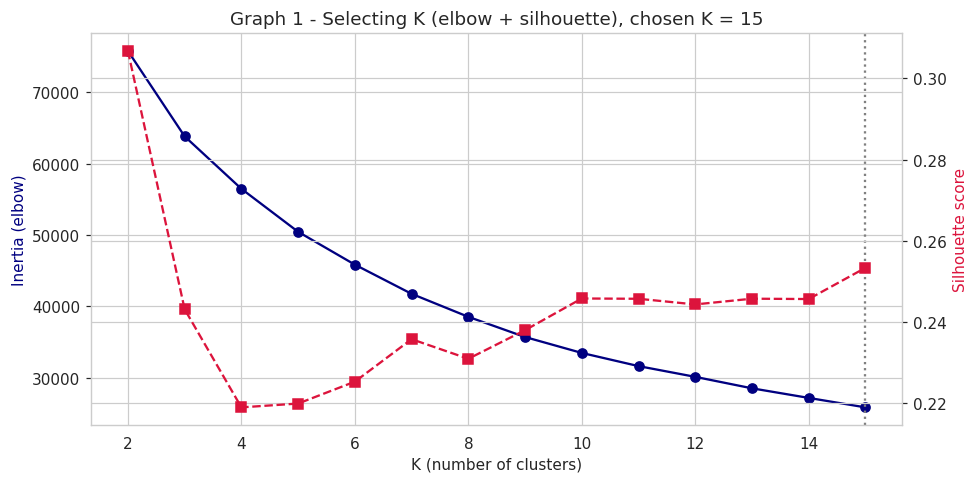

Chosen K = 15


,inertia,silhouette,davies_bouldin
K,,,
2,75799.183,0.307,1.272
3,63823.103,0.243,1.559
4,56471.752,0.219,1.625
5,50443.435,0.220,1.497
6,45836.749,0.225,1.378
7,41745.335,0.236,1.361
8,38519.321,0.231,1.266
9,35687.521,0.238,1.243
10,33455.224,0.246,1.218


In [5]:
K_RANGE = range(2, 16)
rows = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    rows.append((k, km.inertia_,
                 silhouette_score(X, km.labels_, sample_size=6000, random_state=RANDOM_STATE),
                 davies_bouldin_score(X, km.labels_)))
kdf = pd.DataFrame(rows, columns=["K", "inertia", "silhouette", "davies_bouldin"]).set_index("K")

MIN_PRACTICAL_K = 5
K_FINAL = int(kdf.loc[MIN_PRACTICAL_K:, "silhouette"].idxmax())

fig, ax1 = plt.subplots(figsize=(9, 4.5))
ax1.plot(kdf.index, kdf["inertia"], "o-", c="navy"); ax1.set_xlabel("K (number of clusters)")
ax1.set_ylabel("Inertia (elbow)", color="navy")
ax2 = ax1.twinx()
ax2.plot(kdf.index, kdf["silhouette"], "s--", c="crimson"); ax2.set_ylabel("Silhouette score", color="crimson")
ax1.axvline(K_FINAL, ls=":", c="grey")
plt.title(f"Graph 1 - Selecting K (elbow + silhouette), chosen K = {K_FINAL}")
plt.tight_layout(); plt.show()
print("Chosen K =", K_FINAL)
kdf.round(3)

## 6. K-means clustering (Practice 1a)
Partitions the points into K groups by minimising the sum of squared Euclidean distances to the cluster centroid.  
Each **centroid = hotspot centre** (a candidate patrol base).

In [6]:
t0 = time.time()
kmeans = KMeans(n_clusters=K_FINAL, n_init=20, random_state=RANDOM_STATE).fit(X)
t_km = time.time() - t0
df["cluster"] = kmeans.labels_

summary_loc = df.groupby("cluster")[["Latitude", "Longitude"]].mean()
print(f"K-means fitted in {t_km:.2f}s | inertia = {kmeans.inertia_:.1f}")
print(df["cluster"].value_counts().sort_index().to_dict())

K-means fitted in 2.18s | inertia = 25822.3
{0: 931, 1: 2949, 2: 3357, 3: 2679, 4: 2714, 5: 3446, 6: 2169, 7: 3559, 8: 2514, 9: 2637, 10: 3327, 11: 2157, 12: 2579, 13: 1666, 14: 3316}


## 7. Mixture of Gaussians trained with EM (Practice 1b)
Models the data as a weighted sum of K Gaussians. **EM** alternates: *E-step* – compute each point's responsibility (soft membership) for every Gaussian; *M-step* – re-estimate weights, means and covariances.  
We choose the number of components with **BIC** (lower is better) and also fit GMM with the same K for a fair comparison.

In [7]:
sub = rng.choice(len(X), size=min(20000, len(X)), replace=False)
bic = []
for k in K_RANGE:
    g = GaussianMixture(n_components=k, covariance_type="full", n_init=1, random_state=RANDOM_STATE).fit(X[sub])
    bic.append(g.bic(X[sub]))
bic_s = pd.Series(bic, index=list(K_RANGE), name="BIC")
print("GMM BIC (lower is better) - best K by BIC:", int(bic_s.idxmin()))
print(bic_s.round(0).to_string())

t0 = time.time()
gmm = GaussianMixture(n_components=K_FINAL, covariance_type="full", n_init=3, random_state=RANDOM_STATE).fit(X)
t_gmm = time.time() - t0
df["gmm_cluster"] = gmm.predict(X)
df["gmm_confidence"] = gmm.predict_proba(X).max(axis=1)
print(f"GMM fitted in {t_gmm:.2f}s | converged: {gmm.converged_} | EM iterations: {gmm.n_iter_}")
print("Mean assignment confidence:", round(df['gmm_confidence'].mean(), 3))

GMM BIC (lower is better) - best K by BIC: 15
2     188133.0
3     161751.0
4     158031.0
5     136148.0
6     108549.0
7      97355.0
8     104596.0
9      79643.0
10     31108.0
11     -4780.0
12    -48593.0
13    -52006.0
14    -51786.0
15    -57013.0
GMM fitted in 18.10s | converged: True | EM iterations: 31
Mean assignment confidence: 0.978


## 8. Hierarchical (agglomerative) clustering (Practice 1c)
Starts with every point as its own cluster and repeatedly merges the two closest clusters (**Ward linkage** = smallest increase in within-cluster variance). The **dendrogram** shows the merge hierarchy.  
Complexity is O(n²) memory, so it is run on a random subset of 4,000 points.

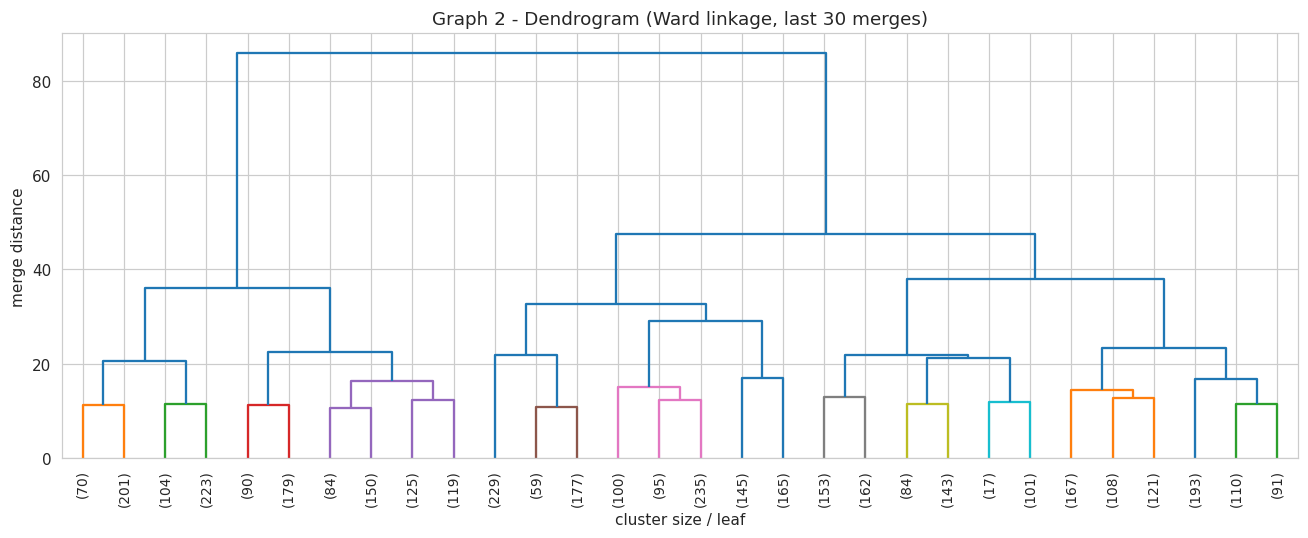

Hierarchical fitted on 4000 points in 0.38s


In [8]:
HC_N = 4000
idx = rng.choice(len(X), size=min(HC_N, len(X)), replace=False)
Xs = X[idx]

Z = linkage(Xs, method="ward")
plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=9, color_threshold=Z[-(K_FINAL - 1), 2])
plt.title("Graph 2 - Dendrogram (Ward linkage, last 30 merges)")
plt.xlabel("cluster size / leaf"); plt.ylabel("merge distance"); plt.tight_layout(); plt.show()

t0 = time.time()
hc = AgglomerativeClustering(n_clusters=K_FINAL, linkage="ward").fit(Xs)
t_hc = time.time() - t0
print(f"Hierarchical fitted on {len(Xs)} points in {t_hc:.2f}s")

## 9. Evaluating the clusterings
No ground-truth labels exist, so we use **internal** validity indices, all computed on the *same* 4,000-point sample for fairness:
* **Silhouette** ↑ – cohesion vs. separation
* **Davies–Bouldin** ↓ – average similarity between clusters
* **Calinski–Harabasz** ↑ – between/within-cluster variance ratio

In [9]:
def evaluate(Xe, labels):
    return (silhouette_score(Xe, labels), davies_bouldin_score(Xe, labels), calinski_harabasz_score(Xe, labels))

res = pd.DataFrame(
    {"K-means":       evaluate(Xs, df.loc[idx, "cluster"].values),
     "GMM (EM)":      evaluate(Xs, df.loc[idx, "gmm_cluster"].values),
     "Hierarchical":  evaluate(Xs, hc.labels_)},
    index=["Silhouette (higher better)", "Davies-Bouldin (lower better)", "Calinski-Harabasz (higher better)"]).T
res["Fit time (s)"] = [t_km, t_gmm, t_hc]
res["Fitted on"] = [f"{len(X):,} pts", f"{len(X):,} pts", f"{len(Xs):,} pts"]
display(res.round(3))

,Silhouette (higher better),Davies-Bouldin (lower better),Calinski-Harabasz (higher better),Fit time (s),Fitted on
K-means,0.250,1.102,1020.789,2.182,"40,000 pts"
GMM (EM),-0.071,3.392,238.312,18.098,"40,000 pts"
Hierarchical,0.170,1.279,832.954,0.378,"4,000 pts"


### Why K-means is our final model
| Criterion | K-means | GMM (EM) | Hierarchical |
|---|---|---|---|
| Scales to 1M+ crime records | ✅ O(n·K·iter) | ✅ but slower, heavier | ❌ O(n²) memory |
| Output = a single **hotspot centre** (patrol base) | ✅ centroid | ⚠ mean + covariance | ❌ no centre |
| Hard zone assignment (needed for allocating units) | ✅ | ⚠ soft probabilities | ✅ |
| Easy to explain to police / stakeholders | ✅ | ⚠ | ✅ dendrogram |
| Re-run on new data each month | ✅ fast | ✅ | ❌ |

K-means gives compact, non-overlapping zones with one centroid each, which maps directly onto *patrol zone → patrol base → units allocated*. GMM is kept as a complementary soft-membership view and hierarchical clustering as a validation of the number of clusters.

## 10. Hotspot analysis (what do the clusters mean?)
For each K-means cluster we compute size, share of all crimes, centroid, peak hour, dominant crime type and approximate density.

In [10]:
def spread_km(g):
    lat0 = g["Latitude"].mean()
    sy = g["Latitude"].std() * 110.57
    sx = g["Longitude"].std() * 111.32 * np.cos(np.radians(lat0))
    return np.pi * (2 * sx) * (2 * sy)      # area of a 2-sigma ellipse, km^2

summary = df.groupby("cluster").agg(
    crimes=("cluster", "size"),
    lat=("Latitude", "mean"), lon=("Longitude", "mean"),
    peak_hour=("Hour", lambda s: int(s.mode()[0])),
    top_crime=("Primary Type", lambda s: s.mode()[0]))
summary["share_%"] = (100 * summary["crimes"] / summary["crimes"].sum()).round(1)
summary["area_km2"] = df.groupby("cluster").apply(spread_km).round(1)
summary["density_per_km2"] = (summary["crimes"] / summary["area_km2"]).round(1)
summary["priority_rank"] = summary["crimes"].rank(ascending=False).astype(int)
summary = summary.sort_values("priority_rank")
display(summary.round(4))
summary.to_csv("hotspot_summary.csv")

,crimes,lat,lon,peak_hour,top_crime,share_%,area_km2,density_per_km2,priority_rank
cluster,,,,,,,,,
7,3559,41.7456,-87.5972,17,BATTERY,8.9,126.6,28.1,1
5,3446,41.8949,-87.7302,15,BATTERY,8.6,110.7,31.1,2
2,3357,41.7495,-87.6041,0,BATTERY,8.4,129.3,26.0,3
10,3327,41.8835,-87.6435,17,THEFT,8.3,71.1,46.8,4
14,3316,41.8973,-87.7372,0,BATTERY,8.3,113.6,29.2,5
1,2949,41.7474,-87.6049,9,THEFT,7.4,136.9,21.5,6
4,2714,41.8997,-87.7347,9,THEFT,6.8,120.9,22.4,7
3,2679,41.8729,-87.6403,12,THEFT,6.7,65.6,40.8,8
9,2637,41.8951,-87.6501,0,THEFT,6.6,90.8,29.0,9


### 📊 Graph 3 - When does each hotspot peak?

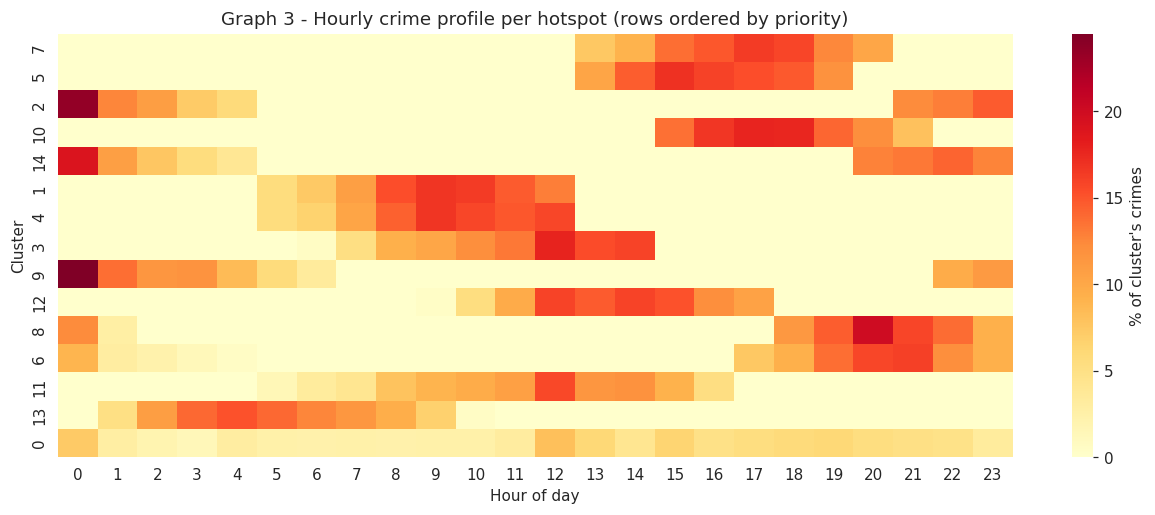

In [11]:
heat = pd.crosstab(df["cluster"], df["Hour"], normalize="index") * 100
plt.figure(figsize=(14, 5))
sns.heatmap(heat.loc[summary.index], cmap="YlOrRd", cbar_kws={"label": "% of cluster's crimes"})
plt.title("Graph 3 - Hourly crime profile per hotspot (rows ordered by priority)"); plt.xlabel("Hour of day"); plt.ylabel("Cluster")
plt.show()

## 11. Resource allocation - how many patrol units per hotspot?
Units are distributed **proportionally to crime volume** (every zone gets at least 1 unit), separately for each shift, so the same total force is shifted to where crime actually occurs at that time of day.

In [12]:
TOTAL_UNITS = 100   # <- change to the real number of patrol units available

def allocate(weights, total, min_each=1):
    w = np.asarray(weights, float)
    alloc = np.full(len(w), min_each)
    raw = w / w.sum() * (total - alloc.sum())
    alloc = alloc + np.floor(raw).astype(int)
    left = total - alloc.sum()
    alloc[np.argsort(-(raw - np.floor(raw)))[:left]] += 1
    return alloc

shift_counts = pd.crosstab(df["cluster"], df["Shift"])
alloc = shift_counts.apply(lambda col: pd.Series(allocate(col.values, TOTAL_UNITS), index=col.index))
alloc["Overall (all day)"] = allocate(summary.sort_index()["crimes"].values, TOTAL_UNITS)
alloc = alloc.loc[summary.index]
display(alloc)

Shift,Night (0-5),Morning (6-11),Afternoon (12-17),Evening (18-23),Overall (all day)
cluster,,,,,
7,1,1,16,11,9
5,1,1,19,8,8
2,23,1,1,11,8
10,1,1,12,13,8
14,18,1,1,14,8
1,3,26,4,1,7
4,2,23,4,1,7
3,1,15,10,1,7
9,23,2,1,5,7


## 12. Patrol route planning
The hotspot centroids are the stops. We build a route that starts at the highest-priority hotspot, uses **nearest-neighbour** for an initial tour and refines it with **2-opt** to remove crossings (a heuristic for the travelling-salesman path; distances in km).

In [13]:
cent = summary[["lat", "lon"]]
lat0 = cent["lat"].mean()
pts = np.c_[cent["lon"] * 111.32 * np.cos(np.radians(lat0)), cent["lat"] * 110.57]
D = np.linalg.norm(pts[:, None] - pts[None], axis=2)
ids = list(cent.index)

def rlen(r): return sum(D[r[i], r[i + 1]] for i in range(len(r) - 1))

# nearest neighbour, start at priority-1 hotspot (row 0)
route, left = [0], set(range(1, len(ids)))
while left:
    nxt = min(left, key=lambda j: D[route[-1], j]); route.append(nxt); left.remove(nxt)
nn_len = rlen(route)

# 2-opt improvement (start point fixed)
improved = True
while improved:
    improved = False
    for i in range(1, len(route) - 1):
        for j in range(i + 1, len(route)):
            new = route[:i] + route[i:j + 1][::-1] + route[j + 1:]
            if rlen(new) < rlen(route) - 1e-9:
                route, improved = new, True

print(f"Nearest-neighbour length: {nn_len:.1f} km  ->  after 2-opt: {rlen(route):.1f} km")
print("Visit order (cluster ids):", [ids[i] for i in route])

Nearest-neighbour length: 52.5 km  ->  after 2-opt: 52.3 km
Visit order (cluster ids): [7, 1, 2, 12, 8, 13, 3, 10, 9, 5, 14, 4, 11, 6, 0]


### 📊 Graph 4 - Hotspot map with the recommended patrol route

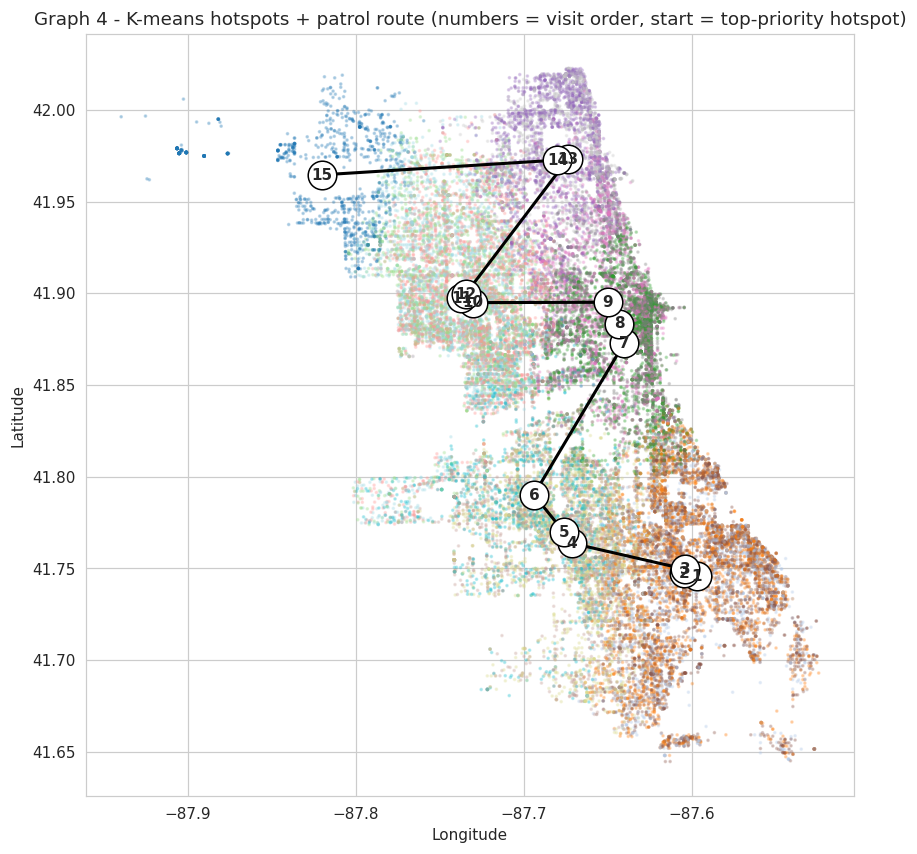

In [14]:
fig, ax = plt.subplots(figsize=(9, 9))
ax.scatter(df["Longitude"], df["Latitude"], c=df["cluster"], cmap="tab20", s=2, alpha=.25)
rl = cent.iloc[route]
ax.plot(rl["lon"], rl["lat"], "-", c="black", lw=2, zorder=4)
for n, (cid, r) in enumerate(rl.iterrows(), 1):
    ax.scatter(r["lon"], r["lat"], s=350, c="white", edgecolor="black", zorder=5)
    ax.text(r["lon"], r["lat"], str(n), ha="center", va="center", weight="bold", zorder=6)
for _, r in cent.iterrows():
    pass
ax.set(title="Graph 4 - K-means hotspots + patrol route (numbers = visit order, start = top-priority hotspot)", xlabel="Longitude", ylabel="Latitude")
plt.show()

## 13. Conclusion
* Crime reports were clustered on **(latitude, longitude, cyclic hour-of-day)**.
* **PCA** showed that location and time contribute independent variance, so all features are retained.
* **K-means, Gaussian Mixture (EM) and Hierarchical clustering** were implemented and compared with Silhouette, Davies-Bouldin and Calinski-Harabasz indices.
* **K-means** was selected: it scales to millions of records, returns an explicit hotspot centre per zone and gives hard assignments that map directly to patrol zones.
* The clusters were converted into **ranked hotspots, shift-wise unit allocation and an optimised patrol route** - directly serving the stated problem statement.

**Limitations / future work:** use DBSCAN/HDBSCAN for irregular street-shaped hotspots, weight crimes by severity, add day-of-week/season, and validate on a different year pulled from the same API.